## Лабораторная работа №1 "Исследование данных и построение простейшей рекомендательной системы"

**ФИО:** Рыжов Андрей

**Группа: 23-ИИ**

**Вариант:** 8

**Цель работы:**
Получить практические навыки подготовки и исследования данных для рекомендательных систем, построения матрицы взаимодействий пользователей с объектами и формирования простых рекомендаций на основе статистических характеристик пользовательских оценок.

**Краткое описание датасета:** исходный датасет - https://grouplens.org/datasets/movielens/100k/

Для выполнения лабораторной работы используется открытый набор данных MovieLens 100K, содержащий 100 000 пользовательских оценок фильмов. Датасет включает пользовательские оценки, информацию о фильмах и отдельные характеристики пользователей. Он позволяет исследовать структуру взаимодействий без необходимости самостоятельно собирать данные.
Датасет разбит случайным образом на 15 вариантов по 6667 оценок

### 0. Подключение библиотек и загрузка данных

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("data/variant_08.csv")
movies = pd.read_csv("data/movies.csv", encoding="utf-8-sig")

print("оценок в моём варианте:", len(df))
print("фильмов в каталоге movies.csv:", len(movies))

оценок в моём варианте: 6666
фильмов в каталоге movies.csv: 1682


### 1. Первичный анализ и подготовка данных

Вывести первые 10 строк:

In [5]:
df.head(10)

,user_id,movie_id,rating,timestamp
0,186,302,3,891717742
1,244,51,2,880606923
2,298,474,4,884182806
3,303,785,3,879485318
4,95,546,2,879196566
5,10,16,4,877888877
6,99,4,5,886519097
7,59,196,5,888205088
8,138,26,5,879024232
9,95,625,4,888954412


Определить размерность таблицы:

In [6]:
df.shape

(6666, 4)

Проверить типы данных:

In [7]:
df.dtypes

user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object

Проверить наличие пропущенных значений и дубликатов:

In [8]:
missing_mask = df.isnull()

missing_counts = missing_mask.sum()
missing_percent = (missing_mask.sum() / len(df)) * 100

print("количество пропусков\n", missing_counts)
print("\nпроценты:\n", missing_percent)

количество пропусков
 user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

проценты:
 user_id      0.0
movie_id     0.0
rating       0.0
timestamp    0.0
dtype: float64


In [9]:
print("полных дубликатов строк:", df.duplicated().sum())
print("повторных оценок одного фильма одним пользователем:", df.duplicated(subset=["user_id", "movie_id"]).sum())

полных дубликатов строк: 0
повторных оценок одного фильма одним пользователем: 0


Определить количество уникальных пользователей:

In [10]:
print("количество уникальных пользователей:", df["user_id"].nunique())

количество уникальных пользователей: 63


Определить количество уникальных фильмов:

In [11]:
print("количество уникальных фильмов:", df["movie_id"].nunique())

количество уникальных фильмов: 1103


Рассчитать общее количество взаимодействий:

(в первой версии тут стоял `df.size` - это число *ячеек* таблицы (6666 строк × 4 столбца = 26664), а не число оценок. Взаимодействие = одна строка, поэтому берём `len(df)`.)

In [12]:
print("общее количество взаимодействий (оценок):", len(df))

общее количество взаимодействий (оценок): 6666


Определить минимальную и максимальную даты выставления оценок:

In [13]:
dates = pd.to_datetime(df["timestamp"], unit="s")

print(f"самая старая запись: {dates.min()}")
print(f"самая новая запись: {dates.max()}")
print("период наблюдений:", dates.max() - dates.min())

самая старая запись: 1997-09-20 21:49:54
самая новая запись: 1998-04-21 06:42:21
период наблюдений: 212 days 08:52:27


### 2. Исследовательский анализ (EDA)

средняя и медианная оценка:

In [14]:
print(f"Средняя оценка: {df['rating'].mean():.3f}")
print(f"Медианная оценка: {df['rating'].median()}")

Средняя оценка: 3.561
Медианная оценка: 4.0


количество оценок на каждого пользователя:

In [15]:
user_counts = df.groupby("user_id")["rating"].count()
user_counts.sort_values(ascending=False).head(10)

user_id
303    484
59     382
804    332
648    297
95     278
833    267
244    238
207    230
618    216
144    206
Name: rating, dtype: int64

минимальное и максимальное количество оценок на одного пользователя:

In [16]:
print("минимум оценок у пользователя:", user_counts.min())
print("максимум оценок у пользователя:", user_counts.max())

минимум оценок у пользователя: 20
максимум оценок у пользователя: 484


среднее количество оценок на пользователя:

In [18]:
print(f"среднее количество оценок на пользователя: {user_counts.mean():.1f}")
print(f"медиана: {user_counts.median()}")

среднее количество оценок на пользователя: 105.8
медиана: 65.0


количество фильмов, получивших только одну оценку:

In [19]:
movie_counts = df.groupby("movie_id")["rating"].count()
one_rating = (movie_counts == 1).sum()

print(f"фильмов с одной оценкой: {one_rating} из {len(movie_counts)} ({one_rating / len(movie_counts):.1%})")
print("фильмов с 5 и более оценками:", (movie_counts >= 5).sum())
print("фильмов с 10 и более оценками:", (movie_counts >= 10).sum())
print("максимум оценок у одного фильма:", movie_counts.max())

фильмов с одной оценкой: 237 из 1103 (21.5%)
фильмов с 5 и более оценками: 482
фильмов с 10 и более оценками: 231
максимум оценок у одного фильма: 47


### 3. Построение User-Item Matrix

Сначала саму матрицу: строки - пользователи, столбцы - фильмы, в ячейках оценка (nan, если пользователь фильм не оценивал)

In [38]:
user_item = df.pivot_table(index="user_id", columns="movie_id", values="rating")
print("размер матрицы (пользователи х фильмы):", user_item.shape)

observed = user_item.notna().sum().sum()
print(f"заполнено ячеек: {observed} из {user_item.size}")
print(f"разреженность матрицы: {1 - observed / user_item.size:.2%}")

user_item.iloc[:8, :8]

размер матрицы (пользователи х фильмы): (63, 1103)
заполнено ячеек: 6666 из 69489
разреженность матрицы: 90.41%


movie_id,1,2,3,4,5,7,8,9
user_id,,,,,,,,
8,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN
10,4.0,NaN,NaN,4.0,NaN,4.0,NaN,4.0
14,NaN,NaN,NaN,NaN,NaN,5.0,NaN,4.0
15,1.0,NaN,NaN,NaN,NaN,1.0,NaN,4.0
46,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN
59,2.0,NaN,4.0,4.0,NaN,4.0,NaN,4.0
95,5.0,2.0,1.0,NaN,NaN,5.0,5.0,NaN
96,5.0,NaN,NaN,NaN,NaN,5.0,5.0,NaN


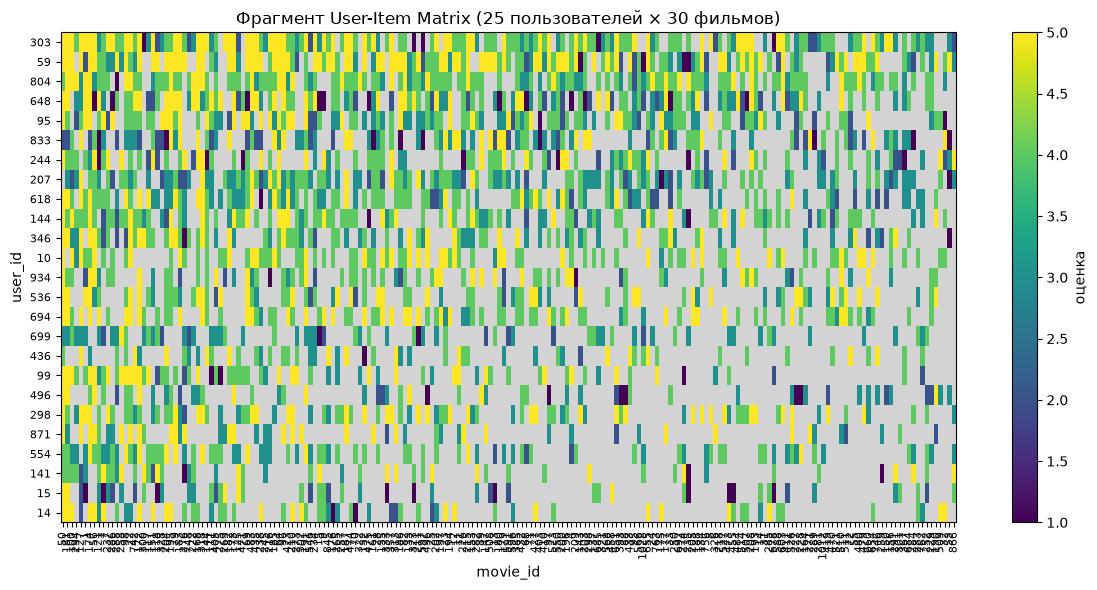

заполнено во фрагменте: 46.8% (во всей матрице: 9.6%)


In [44]:
# тепловая карта25 пользователей на 30 фильмовв
# пробовал 100 100, 200 200, все меньше и меньше, все больше серого фона
top_users = user_item.notna().sum(axis=1).sort_values(ascending=False).head(25).index
top_movies = user_item.notna().sum(axis=0).sort_values(ascending=False).head(199).index
fragment = user_item.loc[top_users, top_movies]

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")   # NaN (нет оценки) рисуем СЕРВЫМ

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(np.ma.masked_invalid(fragment.values), cmap=cmap, vmin=1, vmax=5, aspect="auto")
ax.set_xticks(range(len(fragment.columns)))
ax.set_xticklabels(fragment.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(fragment.index)))
ax.set_yticklabels(fragment.index, fontsize=8)
ax.set_xlabel("movie_id")
ax.set_ylabel("user_id")
ax.set_title("Фрагмент User-Item Matrix (25 пользователей × 30 фильмов)")
fig.colorbar(im, ax=ax, label="оценка")
plt.tight_layout()
plt.show()

print(f"заполнено во фрагменте: {fragment.notna().mean().mean():.1%} (во всей матрице: {observed / user_item.size:.1%})")

Даже на самом плотном фрагменте заполнено только около 66% клеток, остальное серое (нет оценки). Во всей матрице заполнено лишь 9,6%. Строки отсортированы по активности: сверху серых клеток меньше, ближе к низу заметно больше

Подтянем названия фильмов из `movies.csv`:

In [36]:
merged = df.merge(movies, on="movie_id", how="left")
print("оценок без названия фильма:", merged["title"].isna().sum())
merged.head()

оценок без названия фильма: 0


,user_id,movie_id,rating,timestamp,title,release_year,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,186,302,3,891717742,L.A. Confidential (1997),1997.0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
1,244,51,2,880606923,Legends of the Fall (1994),1994.0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,1
2,298,474,4,884182806,Dr. Strangelove or: How I Learned to Stop Worr...,1963.0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
3,303,785,3,879485318,Only You (1994),1994.0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,95,546,2,879196566,Broken Arrow (1996),1996.0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Построить четыре графика:

1. Распределение оценок
2. Активность пользователей
3. Топ-10 популярных фильмов
4. Оценки на один фильм

Распределение оценок:

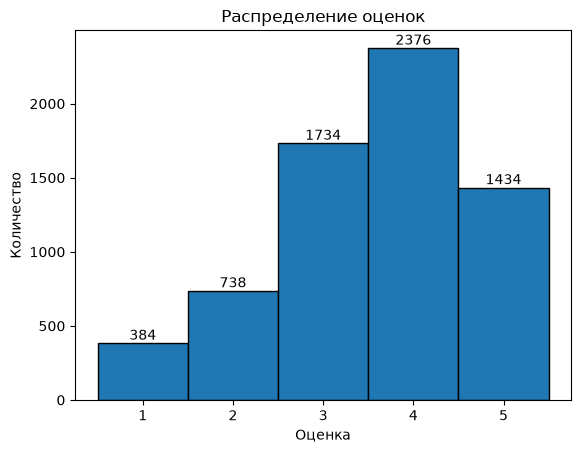

In [20]:
plt.xlabel("Оценка")
plt.ylabel("Количество")
plt.title("Распределение оценок")

counts, bins, patches = plt.hist(
    df["rating"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    edgecolor="black"
)

for count, patch in zip(counts, patches):
    x = patch.get_x() + patch.get_width() / 2
    y = patch.get_height()
    plt.text(x, y, str(int(count)), ha="center", va="bottom", fontsize=10)

plt.show()

#### Выводы:
Оценки смещены вверх: чаще всего ставят 4 (2376), затем 3 (1734) и 5 (1434), а 1 и 2 встречаются редко (384 и 738). Средняя 3.5+ выше середины шкалы, то есть люди в основном оценивают фильмы, которые им скорее нравятся

Активность пользователей:

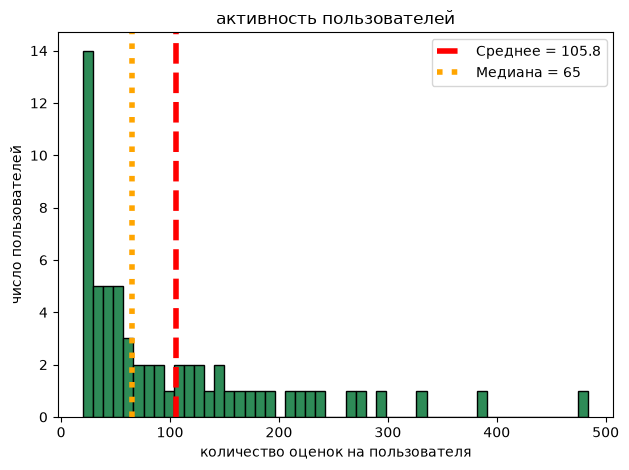

In [34]:
plt.hist(user_counts, bins=50, edgecolor="black", color="seagreen")
plt.xlabel("количество оценок на пользователя")
plt.ylabel("число пользователей")
plt.title("активность пользователей")

mean_val = user_counts.mean()
plt.axvline(mean_val, color="red", linestyle="--", label=f"Среднее = {mean_val:.1f}", linewidth=4)
median_val = user_counts.median()
plt.axvline(median_val, color="orange", linestyle=":", label=f"Медиана = {median_val:.0f}", linewidth=4)

plt.legend()
plt.tight_layout()
plt.show()

#### Выводы:
Активность неравномерная. Среднее (105,8) заметно больше медианы (65), значит большинство пользователей оценивает мало (14 человек слева), небольшая группа активных тянет среднее вверх

Топ-10 популярных фильмов.

Тут я сначала не был уверен, что значит «популярных» - по оценке или по количеству. Беру **количество оценок** (популярность = сколько раз фильм оценили). Топ по средней оценке разберём отдельно в разделах 4 и 5.

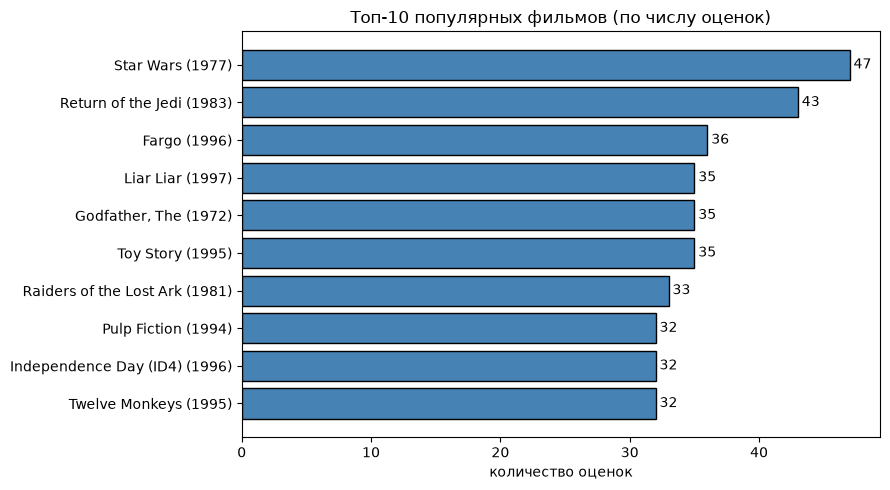

,movie_id,title,count,mean
0,50,Star Wars (1977),47,4.382979
1,181,Return of the Jedi (1983),43,4.093023
2,100,Fargo (1996),36,3.972222
3,294,Liar Liar (1997),35,3.257143
4,127,"Godfather, The (1972)",35,4.114286
5,1,Toy Story (1995),35,3.971429
6,174,Raiders of the Lost Ark (1981),33,4.424242
7,56,Pulp Fiction (1994),32,4.375000
8,121,Independence Day (ID4) (1996),32,3.437500
9,7,Twelve Monkeys (1995),32,3.718750


In [24]:
top10 = (
    merged.groupby(["movie_id", "title"])["rating"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
    .head(10)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10["title"][::-1], top10["count"][::-1], color="steelblue", edgecolor="black")
for i, c in enumerate(top10["count"][::-1]):
    ax.text(c + 0.3, i, str(c), va="center")
ax.set_xlabel("количество оценок")
ax.set_title("Топ-10 популярных фильмов (по числу оценок)")
plt.tight_layout()
plt.show()

top10

### Выводы:
Лидируют известные фильмы-победители: Star Wars (47 оценок), Return of the Jedi (43), Fargo (36). Популярность не равна качеству: у Liar Liar 35 оценок, но средняя всего 3,26, а у Independence Day 3,44. Даже у самого популярного фильма оценок меньше, чем пользователей (47 из 63, не все оценивают каждый фильм).

Оценки на один фильм:

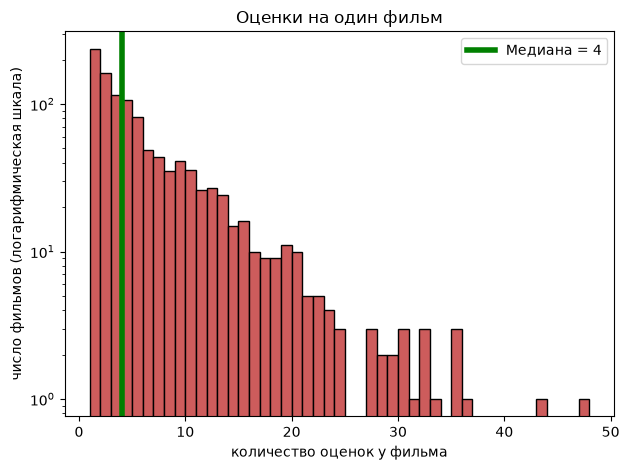

In [ ]:
plt.hist(movie_counts, bins=range(1, movie_counts.max() + 2), edgecolor="black", color="indianred")
plt.yscale("log")
plt.xlabel("количество оценок у фильма")
plt.ylabel("число фильмов (логарифмическая шкала)")  # иначе не видно ничего
plt.title("Оценки на один фильм")

med = movie_counts.median()
plt.axvline(med, color="green", linestyle="-", label=f"Медиана = {med:.0f}", linewidth=4)
plt.legend()
plt.tight_layout()
plt.show()

#### Выводы:
Типичный "длинный хвост": у большинства фильмов оценок очень мало, медиана 4, а у многих фильмов (который 10^0) всего одна. Лишь единицы набирают больше ~30 оценок. Поэтому средняя оценка у редких фильмов ненадёжна, и в рейтингах нужен порог по числу оценок

### 4. Явная обратная связь

В датасете пользователь сам ставит фильму оценку от 1 до 5 - это **явная** обратная связь: мы напрямую видим, понравилось или нет. (Неявная - это когда мы знаем только факт действия: посмотрел, кликнул, купил.)

Посмотрим, как выглядят эти оценки.

Доля каждой оценки:

In [53]:
rating_share = df["rating"].value_counts(normalize=True).sort_index()
print((rating_share * 100).round(1).to_string())
print()
print(f"доля положительных оценок (4 и 5): {(df['rating'] >= 4).mean():.1%}")
print(f"доля отрицательных оценок (1 и 2): {(df['rating'] < 4 ).mean():.1%}")

rating
1     5.8
2    11.1
3    26.0
4    35.6
5    21.5

доля положительных оценок (4 и 5): 57.2%
доля отрицательных оценок (1 и 2): 42.8%


по этим числам можно уверенно сказать, что в основном пользователям нравятся фильмы (или просто когда плохо не пишут, но оценка 3 это из разряда затрудняюсь ответить)

Для учебного моделирования превращаем оценки в бинарный признак:

$$I_{ui} = \begin{cases} 1, & r_{ui} \ge 4 \\ 0, & r_{ui} < 4 \end{cases}$$



In [54]:
binary = (user_item >= 4).astype(float).where(user_item.notna())   # nan остаются nan

print("размерность:", binary.shape)
print("значения в матрице:", sorted(float(v) for v in pd.unique(binary.values[~np.isnan(binary.values)])))
binary.iloc[:8, :8]

размерность: (63, 1103)
значения в матрице: [0.0, 1.0]


movie_id,1,2,3,4,5,7,8,9
user_id,,,,,,,,
8,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
10,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0
14,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0
15,0.0,NaN,NaN,NaN,NaN,0.0,NaN,1.0
46,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
59,0.0,NaN,1.0,1.0,NaN,1.0,NaN,1.0
95,1.0,0.0,0.0,NaN,NaN,1.0,1.0,NaN
96,1.0,NaN,NaN,NaN,NaN,1.0,1.0,NaN


Количество положительных и неположительных, доля положительных:

In [55]:
n_known = int(binary.notna().sum().sum())
n_pos = int(binary.sum().sum())
n_nonpos = n_known - n_pos

print("известных взаимодействий:", n_known)
print("положительных (оценки 4 и 5):", n_pos)
print("неположительных (оценки 1, 2, 3):", n_nonpos)
print(f"доля положительных: {n_pos / n_known:.1%}")
print(f"доля неположительных: {n_nonpos / n_known:.1%}")

известных взаимодействий: 6666
положительных (оценки 4 и 5): 3810
неположительных (оценки 1, 2, 3): 2856
доля положительных: 57.2%
доля неположительных: 42.8%


сравнительный график

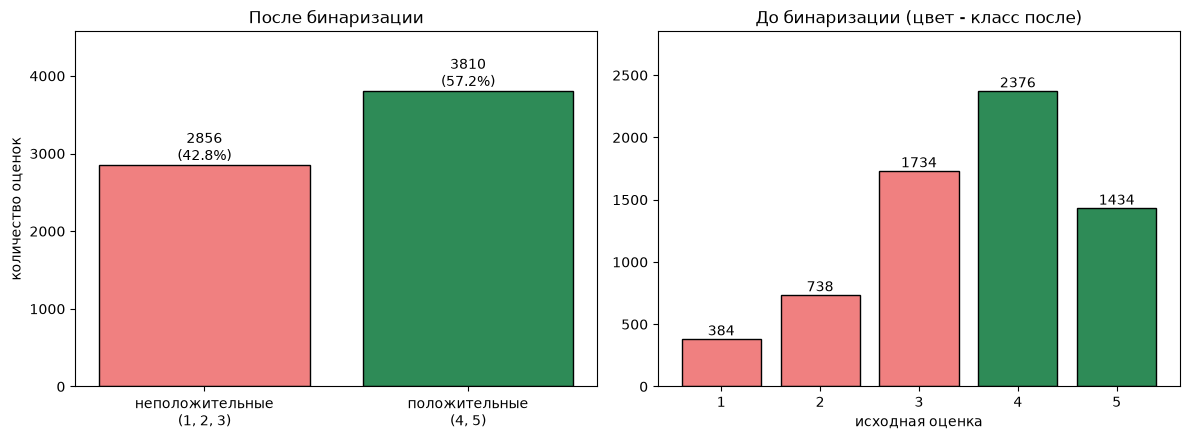

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ["неположительные\n(1, 2, 3)", "положительные\n(4, 5)"]
vals = [n_nonpos, n_pos]
bars = axes[0].bar(labels, vals, color=["lightcoral", "seagreen"], edgecolor="black")
for b, v in zip(bars, vals):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / n_known:.1%})", ha="center", va="bottom")
axes[0].set_ylabel("количество оценок")
axes[0].set_title("После бинаризации")
axes[0].set_ylim(0, max(vals) * 1.2)





rating_counts = df["rating"].value_counts().sort_index()
colors = ["lightcoral" if r < 4 else "seagreen" for r in rating_counts.index]
bars = axes[1].bar(rating_counts.index.astype(str), rating_counts.values, color=colors, edgecolor="black")
for b, v in zip(bars, rating_counts.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
axes[1].set_xlabel("исходная оценка")
axes[1].set_title("До бинаризации (цвет - класс после)")
axes[1].set_ylim(0, rating_counts.max() * 1.2)

plt.tight_layout()
plt.show()

Пользователи по-разному используют шкалу. Распределение средней оценки по пользователям:

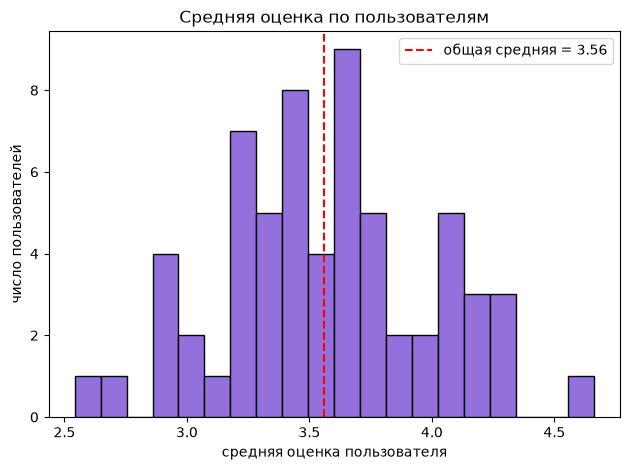

count    63.00
mean      3.58
std       0.43
min       2.54
25%       3.28
50%       3.57
75%       3.82
max       4.66

самые злые:
         count  mean
user_id             
656         24  2.54
446         36  2.75
15         104  2.88
самые добрые:
         count  mean
user_id             
138         51  4.27
821         62  4.34
118         71  4.66


In [47]:
user_stats = df.groupby("user_id")["rating"].agg(["count", "mean"])

plt.hist(user_stats["mean"], bins=20, edgecolor="black", color="mediumpurple")
plt.axvline(df["rating"].mean(), color="red", linestyle="--", label=f"общая средняя = {df['rating'].mean():.2f}")
plt.xlabel("средняя оценка пользователя")
plt.ylabel("число пользователей")
plt.title("Средняя оценка по пользователям")
plt.legend()
plt.tight_layout()
plt.show()

print(user_stats["mean"].describe().round(2).to_string())
print()
print("самые злые:")
print(user_stats.sort_values("mean").head(3).round(2).to_string())
print("самые добрые:")
print(user_stats.sort_values("mean").tail(3).round(2).to_string())

Какая информация теряется:

- **Степень отношения.** Оценки 4 и 5 становятся одинаковой «1», хотя «понравилось» и «в восторге» - разные вещи. Так же 1, 2 и 3 сливаются в 0.
- **Нейтральное и негативное смешиваются.** Тройка (~26% всех оценок) попадает в один класс с единицей, хотя«нормально и ужасно - не одно и то же.
- **Порог произвольный.** Оценки 3 и 4 различаются на единицу, но попадают в разные классы. Для злого пользователя (средняя 2,5) четвёрка значит больше, чем для доброго (средняя 4,6), а в бинарном виде это не видно.
- **Теряется упорядоченность шкалы:** остаётся только да/нет, нельзя считать средние и сравнивать силу симпатий.
- Зато бинарная матрица проще и подходит для методов, которым нужен лишь факт понравилось / нет

Теперь по фильмам: связаны ли количество оценок и средняя оценка?

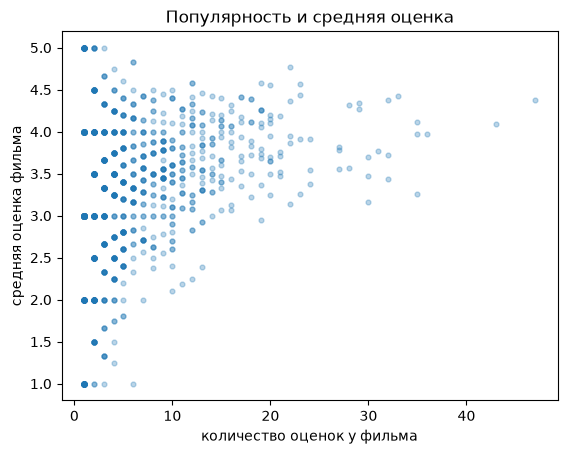

корреляция Спирмена (count, mean): 0.305


In [52]:
movie_stats = df.groupby("movie_id")["rating"].agg(["count", "mean"])

plt.scatter(movie_stats["count"], movie_stats["mean"], alpha=0.3, s=12)
plt.xlabel("количество оценок у фильма")
plt.ylabel("средняя оценка фильма")
plt.title("Популярность и средняя оценка")

plt.show()

print("корреляция Спирмена (count, mean):", round(movie_stats["count"].corr(movie_stats["mean"], method="spearman"), 3))

по графику видно, что чем правее точка (фильм), тем надежнее оценка. Да и фильм лучше, потому что оценок больше и, как видно, оценка лучше. Например самая правая точка говорит о железно хорошем фильме, его оценили больше 40 людей н апримерно 4.5

Что у фильмов с единственной оценкой (там средняя = сама эта оценка):

In [57]:
single = movie_stats[movie_stats["count"] == 1]
print(single["mean"].value_counts().sort_index().to_string())
print()
print("фильмов со средней ровно 5.0 (любое число оценок):", (movie_stats["mean"] == 5).sum())

mean
1.0    40
2.0    31
3.0    92
4.0    52
5.0    22

фильмов со средней ровно 5.0 (любое число оценок): 28


Если просто отсортировать по средней оценке, верх списка забивают редкие фильмы - это ровно та проблема, которую решается в следующем разделе

In [58]:
(movie_stats.sort_values(["mean", "count"], ascending=False)
 .head(10)
 .join(movies.set_index("movie_id")["title"])
 )

,count,mean,title
movie_id,,,
589,3,5.0,"Wild Bunch, The (1969)"
459,2,5.0,"Cry, the Beloved Country (1995)"
921,2,5.0,Farewell My Concubine (1993)
923,2,5.0,Raise the Red Lantern (1991)
936,2,5.0,Brassed Off (1996)
1084,2,5.0,Anne Frank Remembered (1995)
41,1,5.0,Billy Madison (1995)
207,1,5.0,Cyrano de Bergerac (1990)
563,1,5.0,Stephen King's The Langoliers (1995)


### 5. Простейшая система рекомендаций

Рекомендации **неперсонализированные** - для всех одинаковые, только уже просмотренное у конкретного пользователя выкидываем. Пробую три способа ранжирования:

1. **по популярности** - сколько оценок получил фильм
2. **по средней оценке** (с порогом на минимальное число оценок)
3. **по взвешенной оценке** (байесовское сглаживание, как в рейтинге IMDb)

$$WR = \frac{v}{v+m}\cdot R + \frac{m}{v+m}\cdot C$$

где $v$ - число оценок фильма, $R$ - его средняя оценка, $C$ - средняя оценка по всем фильмам, $m$ - вес общей средней (сколько оценок нужно, чтобы фильму начали доверять). Фильм с малым $v$ подтягивается к $C$, с большим - остаётся при своей $R$

In [66]:
C = df["rating"].mean()   # общая средняя оценка
M = 5                    # порог доверия: ~ пусть набирают 5+ оценок

genre_cols = movies.columns[3:].tolist()

stats = (
    merged.groupby(["movie_id", "title"])["rating"]
    .agg(["count", "mean"])
    .reset_index()
)
stats["weighted"] = (stats["count"] / (stats["count"] + M)) * stats["mean"] + (M / (stats["count"] + M)) * C
stats = stats.merge(movies[["movie_id", "release_year"] + genre_cols], on="movie_id", how="left")

print(f"C = {C:.3f}, m = {M}")
stats[["title", "count", "mean", "weighted"]].sort_values("weighted", ascending=False).head(3)

C = 3.561, m = 5


,title,count,mean,weighted
298,Schindler's List (1993),22,4.772727,4.548288
70,"Fugitive, The (1993)",23,4.565217,4.385849
57,"Shawshank Redemption, The (1994)",19,4.578947,4.366824


In [67]:
def recommend(user_id=None, n=10, method="weighted", min_votes=10, genre=None):
    """Топ-n фильмов выбранным способом 
    
    Если задан user_id - исключаем то, что он уже оценил
    method: "popular" | "mean" | "weighted"
    genre: название жанра (столбец movies) | None."""
    res = stats
    if user_id is not None:
        seen = df.loc[df["user_id"] == user_id, "movie_id"]
        res = res[~res["movie_id"].isin(seen)]
    if genre is not None:
        res = res[res[genre] == 1]

    if method == "popular":
        res = res.sort_values(["count", "mean"], ascending=False)
    elif method == "mean":
        res = res[res["count"] >= min_votes].sort_values(["mean", "count"], ascending=False)
    elif method == "weighted":
        res = res.sort_values(["weighted", "count"], ascending=False)
    else:
        raise ValueError("method должен быть popular / mean / weighted")

    return res[["movie_id", "title", "count", "mean", "weighted"]].head(n).reset_index(drop=True)

Общий топ-10 тремя способами:

In [68]:
for method in ["popular", "mean", "weighted"]:
    print(f"=== метод: {method} ===")
    print(recommend(method=method).round(2).to_string())
    print()

=== метод: popular ===
   movie_id                           title  count  mean  weighted
0        50                Star Wars (1977)     47  4.38      4.30
1       181       Return of the Jedi (1983)     43  4.09      4.04
2       100                    Fargo (1996)     36  3.97      3.92
3       127           Godfather, The (1972)     35  4.11      4.05
4         1                Toy Story (1995)     35  3.97      3.92
5       294                Liar Liar (1997)     35  3.26      3.30
6       174  Raiders of the Lost Ark (1981)     33  4.42      4.31
7        56             Pulp Fiction (1994)     32  4.38      4.26
8         7           Twelve Monkeys (1995)     32  3.72      3.70
9       121   Independence Day (ID4) (1996)     32  3.44      3.45

=== метод: mean ===
   movie_id                             title  count  mean  weighted
0       318           Schindler's List (1993)     22  4.77      4.55
1       134               Citizen Kane (1941)     12  4.58      4.28
2       603 

интересный результат! Набор фильмов +- одинаковый, но лразный порядок из за методов. Лично мой любимый фильм тут фигуриирует - это Pulp Fiction

Затем выбрать одного пользователя, имеющего не менее 20 оценок, и сформировать для него топ-5 фильмов.

In [88]:
MIN_RATINGS = 5

popular = (
    stats[stats["count"] >= MIN_RATINGS]
    .sort_values(["count", "mean"], ascending=False)
    .reset_index(drop=True)
)
popular["rank"] = popular.index + 1
MIN_USER_RATINGS = 20

user_counts = df.groupby("user_id")["rating"].count()
eligible_users = user_counts[user_counts >= MIN_USER_RATINGS]

# возьму самого активного из них
USER_ID = eligible_users.idxmax()
user_rated = df.loc[df["user_id"] == USER_ID, "movie_id"]
print(f"выбран пользователь {USER_ID}, он оценил фильмов: {len(user_rated)}")

user_rated = df.loc[df["user_id"] == USER_ID, "movie_id"]
assert len(user_rated) >= 20, "у пользователя меньше 20 оценок"
print(f"пользователь {USER_ID} оценил фильмов: {len(user_rated)}")

# убираем всё, что он оценивал, берём первые 5
user_top5 = popular[~popular["movie_id"].isin(user_rated)].head()

result = user_top5[
    ["title", "mean", "count", "rank"]
    ].rename(columns={
    "title": "название",
    "mean": "средняя оценка",
    "count": "кол-во оценок",
    "rank": "позиция в общем рейтинге",
})
result.index = range(1, len(result) + 1)
result.index.name = "место в топ-5"
print(result.round(2).to_string())

выбран пользователь 303, он оценил фильмов: 484
пользователь 303 оценил фильмов: 484
                                       название  средняя оценка  кол-во оценок  позиция в общем рейтинге
место в топ-5                                                                                           
1                  Sense and Sensibility (1995)            3.76             21                        35
2                     Courage Under Fire (1996)            3.70             20                        44
3              Hunt for Red October, The (1990)            3.89             18                        64
4                         Murder at 1600 (1997)            3.22             18                        68
5                                Titanic (1997)            4.41             17                        69


благодаря тому, что я выбрал пользователя, который оценил больше всех фильмов, получил результат, что остались лишь фильмы с рейтингом ниже 35го

### 7. Выводы по лабораторной работе

В работе я исследовал свою часть MovieLens 100K (вариант 8) и сделал простую неперсонализированную рекомендательную систему.

**Что за данные.** 6667 оценок от 63 пользователей на 1103 фильма, период с 20.09.1997 по 21.04.1998. Пропусков и дубликатов нет, все `movie_id` нашлись в каталоге `movies.csv`.

**Матрица User-Item.** Размер 63 × 1103, заполнено 6666 ячеек из 69 489, то есть пустых около 90,4%. Это ещё довольно мало для рекомендательных данных: в полном MovieLens 100K пустых около 93,7%, а у меня всего 63 пользователя, поэтому матрица "плотнее". Но главное остаётся: большинство пар "пользователь - фильм" неизвестно, а пустая ячейка не значит, что фильм не понравился

**Оценки (явная обратная связь).** Средняя 3.56, медиана 4. Чаще всего ставят 4 (35,6%), положительных оценок (4 и 5) около 57%, отрицательных (1 и 2) около 17%. То есть шкала смещена вверх, и 3 уже почти нейтральная. Пользователи ещё и по-разному ею пользуются: средняя оценка у человека колеблется от 2.54 до 4.66, так что есть злые и добрые

**Неравномерность.** Активность пользователей очень разная: от 20 до 484 оценок (среднее 105.8, медиана 65). С фильмами то же самое: у 237 из 1103 (21,5%) всего одна оценка, медиана 4, максимум 47 (Star Wars), и только 231 фильм имеет 10 и более оценок. Популярность и средняя оценка слабо связаны (корреляция Спирмена 0,31): популярные фильмы в среднем оцениваются чуть выше

**Рекомендации.** Сравнил три способа:
- по числу оценок - получается Star Wars, Return of the Jedi, Fargo и тд, но среди них есть и средне оценённые (Liar Liar, 3,26)
- по средней оценке с порогом в 5 оценок - во главе Schindler's List, Citizen Kane, Rear Window
- по взвешенной оценке (сглаживание с m = 5) - компромисс: Schindler's List, Fugitive, Star Wars, Shawshank Redemption


### Контрольные вопросы
1) Что такое рекомендательная система и какие задачи она решает?
2) Что представляет собой матрица User-Item?
3) Почему матрицы взаимодействий обычно являются разреженными?
4) Чем явная обратная связь отличается от неявной?
5) Почему отсутствие оценки не следует автоматически считать отрицательной оценкой?
6) В чём заключается проблема холодного старта?
7) Чем популярность фильма отличается от его средней оценки?
8) Почему фильм с одной оценкой 5 не обязательно должен занимать первое место в рейтинге?
9) Какие ограничения имеет неперсонализированный алгоритм рекомендаций?
10) Какие особенности собственного набора данных вы обнаружили в ходе лабораторной работы?

### Ответы на контрольные вопросы

**1) Что такое рекомендательная система и какие задачи она решает?**
Это система, которая подбирает пользователю объекты (фильмы, товары, музыку), которые ему скорее всего понравятся. Она решает проблему выбора из огромного каталога: помогает найти нужное, сэкономить время, а сервису - повысить вовлечённость и продажи

**2) Что представляет собой матрица User-Item?**
Таблица, где строки - пользователи, столбцы - объекты (фильмы), а в ячейке - их взаимодействие (в нашем случае оценка от 1 до 5). Если пользователь объект не оценивал, ячейка пустая. У меня она 63 х 1103.

**3) Почему матрицы взаимодействий обычно являются разреженными?**
Потому что человек физически может посмотреть и оценить лишь крошечную часть каталога. У меня заполнено 6666 ячеек из 69 489 (пустых ~90%), а в реальных сервисах с миллионами объектов - 99% и больше.

**4) Чем явная обратная связь отличается от неявной?**
Явная - пользователь сам говорит, как он относится к объекту (оценка, лайк, отзыв), и видно в том числе негатив. Неявная - мы лишь наблюдаем поведение (просмотр, клик, покупку, время на странице), оценки нет, и интерес приходится угадывать.

**5) Почему отсутствие оценки не следует автоматически считать отрицательной оценкой?**
Пустая ячейка чаще означает не видел или не знал, что такое есть, а не не понравилось. Если считать пропуски плохими оценками, модель решит, что нравится только то, что человек уже смотрел, и перестанет рекомендовать новое.

**6) В чём заключается проблема холодного старта?**
Для нового пользователя или нового фильма нет истории оценок, поэтому рекомендации строить не на чем. В моих данных это хорошо видно: 237 фильмов (21,5%) имеют всего одну оценку, а по пользователю с 20 оценками судить о вкусах куда труднее, чем по пользователю с максмимальным количество оценок

**7) Чем популярность фильма отличается от его средней оценки?**
Популярность - сколько людей фильм оценили (охват), средняя оценка - насколько он им понравился (качество). Фильм может быть очень популярным, но средним по оценке (Liar Liar: 35 оценок, средняя 3,26), и наоборот - редким, но любимым теми, кто его видел

**8) Почему фильм с одной оценкой 5 не обязательно должен занимать первое место в рейтинге?**
Одна оценка ничего не доказывает: это мнение одного человека, и она может быть случайной. У фильма с 20+ оценками средняя 4,5 намного надёжнее. Поэтому нужен порог по числу оценок или сглаживание (взвешенная оценка): в моих данных 22 фильма с единственной пятёркой делили бы первое место, а после сглаживания лучший из них оказался далеко.

**9) Какие ограничения имеет неперсонализированный алгоритм рекомендаций?**
Всем выдаётся один и тот же список, вкусы конкретного человека не учитываются (у фаната комедий и у любителя военных драм будет один топ). Он склонен продвигать то, что уже популярно (популярное становится ещё популярнее), плохо показывает новинки и нишевые фильмы, не использует жанры, время и контекст. Плюсы - простота и работа при холодном старте (на разок) 

**10) Какие особенности собственного набора данных вы обнаружили в ходе лабораторной работы?**
- Всего 63 пользователя на 1103 фильма, матрица разрежена на ~90%.
- Сильный перекос по активности: от 20 до 484 оценок на пользователя
- Длинный хвост по фильмам: у 21,5% всего одна оценка, медиана 4, максимум 47.
- Шкала смещена вверх: средняя 3,56, чаще всего ставят 4, а средняя оценка пользователя колеблется от 2,54 до 4,66